# Silt Random Forest — 20/21 Feb Sentinel-1 + same-orbit change + Dragonfly labels

Supervised silt map after Cyclone Gabrielle.

| Input | Role |
|---|---|
| Dragonfly `category` in `{silt, slip}` (19/21 Feb 2023) | Training labels (positive class) |
| Sentinel-1 IW GRD on **20 or 21 Feb** (closest to the silt date) | Post-event SAR |
| Earlier scene with the **same relative orbit and pass** | Pre-event SAR |
| Paper-informed post-event `VV³`, `(VV+VH)⁶`, `(VV×VH)³`; plus `ΔVV`, `ΔVH`, `angle` | RF features |

Lecture 6 style: `smileRandomForest` on dual-pol SAR, speckle = `focal_mean(50 m)`. PODPC features follow Ma et al. (2024); temporal change and angle are project additions. The class is **silt vs not silt**, not land vs water.

Dragonfly silt is a Sentinel-2 model product (CC BY-SA 3.0 IGO), not a field survey. **Train** on Dragonfly labels **outside** the mapping AOI (a larger buffer). **Test** only inside the AOI.


## 0. Config and Earth Engine


In [10]:
import math
import sys, importlib, io, re
from datetime import datetime, timedelta, timezone
from pathlib import Path

import ee
import geemap
import geopandas as gpd
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Patch
from PIL import Image
from shapely.geometry import box
from urllib.request import urlopen

_root = Path.cwd()
_nb = _root / "notebooks" if (_root / "notebooks" / "layer_config.py").exists() else _root
sys.path.insert(0, str(_nb))
import layer_config as cfg
importlib.reload(cfg)

_repo = _root if (_root / "processing" / "ee_auth.py").exists() else _root.parent
if str(_repo) not in sys.path:
    sys.path.insert(0, str(_repo))
from processing.ee_auth import initialize_ee

initialize_ee()

aoi = cfg.aoi_geometry()          # test / map region
SCALE = cfg.WORKING_SCALE
SAMPLE_SCALE = 20                # sample at 20 m (4× fewer pixels than 10 m)
AREA_SCALE = 20
N_TREES = 50
SILT_PROB_MIN = 0.5             # below 0.5 to raise silt recall (FN was ~half at 0.5)
SILT_TRAIN_MULT = 1.5             # oversample positives so the RF is biased toward silt
N_SAMPLES_TRAIN = 100            # not-silt count outside AOI; silt count × SILT_TRAIN_MULT
N_SAMPLES_TEST = 50             # silt and not-silt each, AOI only (balanced, for recall)
SPECKLE_M = 50
TRAIN_BUFFER_KM = 10.0           # outer square; training excludes the inner AOI
POST_START = "2023-02-20"
POST_END = "2023-02-22"          # exclusive-style: 20 and 21 Feb
PRE_LOOKBACK_DAYS = 90           # search same-orbit pre-event scenes
PRE_END = cfg.FLOOD_PEAK_DATE    # do not use the 14 Feb flood scene as "pre"

IMPACT_DIR = _repo / "data" / "raw" / "validation" / "dragonfly_impact_20230221"
OUT_DIR = _repo / "outputs" / "silt_layer"
OUT_DIR.mkdir(parents=True, exist_ok=True)

lat, lon = cfg.MAP_CENTER
_dlat = TRAIN_BUFFER_KM / 111.32
_dlon = TRAIN_BUFFER_KM / (111.32 * math.cos(math.radians(lat)))
TRAIN_BOUNDS = [lon - _dlon, lat - _dlat, lon + _dlon, lat + _dlat]  # west, south, east, north
train_geom = ee.Geometry.Rectangle(TRAIN_BOUNDS, geodesic=False)
train_region = train_geom.difference(aoi, 1)  # outside AOI only

print("AOI (test):", cfg.MAP_CENTER, f"±{cfg.AOI_RADIUS_KM} km")
print("Train buffer: ±", TRAIN_BUFFER_KM, "km minus AOI")
print("Post window:", POST_START, "→", POST_END, "| pre-event before:", PRE_END)


AOI (test): [-39.58, 176.88] ±5.0 km
Train buffer: ± 10.0 km minus AOI
Post window: 2023-02-20 → 2023-02-22 | pre-event before: 2023-02-14


## 1. Dragonfly silt labels

Positive class = Dragonfly `silt` **and** `slip`. Negatives are everything else (including Dragonfly `flood`). **Permanent water is dropped** from train and test, not used as a class.

Local GeoPackage (NZTM2000). Silt timestamps are `19-02-2023, 21-02-2023`; the SAR target is the midpoint **20 Feb**.


In [11]:
assert IMPACT_DIR.is_dir(), f"Missing {IMPACT_DIR}"
impact_path = next(IMPACT_DIR.glob("*.gpkg"), None) or next(IMPACT_DIR.glob("*.shp"))

train_2193 = gpd.GeoSeries([box(*TRAIN_BOUNDS)], crs=4326).to_crs(2193)
impact = gpd.read_file(impact_path, bbox=tuple(train_2193.total_bounds)).to_crs(4326)
impact = gpd.clip(impact, box(*TRAIN_BOUNDS))
impact = impact[~impact.geometry.is_empty].copy()
print(impact_path.name)
print(impact.groupby(["date", "source", "category"]).size())

POSITIVE_CLASSES = ("silt", "slip")  # both count as the silt-class label
silt = impact[impact["category"].isin(POSITIVE_CLASSES)].copy()
assert len(silt) > 0, "No silt/slip polygons in the train buffer."
print("Positive labels:", silt["category"].value_counts().to_string())
flood_poly = impact[impact["category"] == "flood"].copy()

def parse_dates(value):
    return [datetime.strptime(x, "%d-%m-%Y").date() for x in re.findall(r"\d{2}-\d{2}-\d{4}", str(value))]

silt_days = sorted({d for value in silt["date"] for d in parse_dates(value)})
target_date = silt_days[0] + (silt_days[-1] - silt_days[0]) / 2
print("Silt days:", silt_days, "| S1 target:", target_date)

def to_ee_mask(gdf):
    if gdf is None or gdf.empty:
        return ee.Image(0).clip(train_geom)
    g = gdf.copy()
    g["geometry"] = g.geometry.simplify(0.00005)
    g = g[~g.geometry.is_empty]
    if g.empty:
        return ee.Image(0).clip(train_geom)
    return ee.Image(0).paint(geemap.gdf_to_ee(g[["geometry"]]), 1).clip(train_geom)

silt_img = to_ee_mask(silt).rename("silt")
df_flood_img = to_ee_mask(flood_poly).rename("df_flood")


Gabrielle-cyclone-impact_HawkesBay-Gisborne-regions.gpkg
date                    source      category
19-02-2023, 21-02-2023  Sentinel-2  silt        2985
                                    slip        1049
20-02-2023              Sentinel-1  flood        223
dtype: int64
Positive labels: category
silt    2985
slip    1049
Silt days: [datetime.date(2023, 2, 19), datetime.date(2023, 2, 21)] | S1 target: 2023-02-20


## 2. Post-event Sentinel-1 (20/21 Feb) and same-orbit pre-event scene

IW, 10 m, VV/VH. Both passes are allowed in the 20–21 Feb window; the closest scene to the silt midpoint is kept. Pre-event is the latest scene **before** `FLOOD_PEAK_DATE` with the same `relativeOrbitNumber_start` and `orbitProperties_pass`.


In [12]:
def s1_iw(start, end):
    return (
        ee.ImageCollection("COPERNICUS/S1_GRD")
        .filterBounds(train_geom)
        .filterDate(start, end)
        .filter(ee.Filter.eq("instrumentMode", "IW"))
        .filter(ee.Filter.eq("resolution_meters", 10))
        .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
        .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH"))
        .select(["VV", "VH", "angle"])
    )

def with_offset(img, target):
    hours = img.date().difference(target, "hour")
    return img.set({"hours_from_target": hours, "abs_hours_from_target": hours.abs()})

target_ee = ee.Date(target_date.isoformat())
post_col = s1_iw(POST_START, POST_END).map(lambda img: with_offset(img, target_ee))
assert post_col.size().getInfo() > 0, "No 20/21 Feb Sentinel-1 scenes. Check AOI coverage."

def scene_rows(col, limit=12):
    rows = []
    for f in col.sort("abs_hours_from_target").limit(limit).getInfo()["features"]:
        p = f["properties"]
        rows.append({
            "scene_id": p["system:index"],
            "acquired_utc": datetime.fromtimestamp(p["system:time_start"] / 1000, timezone.utc).isoformat(),
            "pass": p.get("orbitProperties_pass"),
            "rel_orbit": p.get("relativeOrbitNumber_start"),
            "hours_from_target": round(p["hours_from_target"], 1),
        })
    return pd.DataFrame(rows)

print("Post-event candidates (20–21 Feb)")
display(scene_rows(post_col))

s1_post_raw = ee.Image(post_col.sort("abs_hours_from_target").first())
post_p = s1_post_raw.getInfo()["properties"]
post_id = post_p["system:index"]
post_time = datetime.fromtimestamp(post_p["system:time_start"] / 1000, timezone.utc)
post_pass = post_p["orbitProperties_pass"]
post_orbit = int(post_p["relativeOrbitNumber_start"])
print("Selected POST:", post_id, post_time.isoformat(), post_pass, "orbit", post_orbit)

pre_start = (datetime.fromisoformat(PRE_END) - timedelta(days=PRE_LOOKBACK_DAYS)).date().isoformat()
pre_col = (
    s1_iw(pre_start, PRE_END)
    .filter(ee.Filter.eq("relativeOrbitNumber_start", post_orbit))
    .filter(ee.Filter.eq("orbitProperties_pass", post_pass))
)
assert pre_col.size().getInfo() > 0, (
    f"No same-orbit pre-event scene (orbit {post_orbit} {post_pass} before {PRE_END})."
)
s1_pre_raw = ee.Image(pre_col.sort("system:time_start", False).first())
pre_p = s1_pre_raw.getInfo()["properties"]
pre_id = pre_p["system:index"]
pre_time = datetime.fromtimestamp(pre_p["system:time_start"] / 1000, timezone.utc)
print("Selected PRE :", pre_id, pre_time.isoformat(), pre_p.get("orbitProperties_pass"), "orbit", pre_p.get("relativeOrbitNumber_start"))


Post-event candidates (20–21 Feb)


,scene_id,acquired_utc,pass,rel_orbit,hours_from_target
0,S1A_IW_GRDH_1SDV_20230220T172223_20230220T1722...,2023-02-20T17:22:23+00:00,DESCENDING,175,17.4
1,S1A_IW_GRDH_1SDV_20230221T065920_20230221T0659...,2023-02-21T06:59:20+00:00,ASCENDING,8,31.0


Selected POST: S1A_IW_GRDH_1SDV_20230220T172223_20230220T172248_047322_05AE03_C8CF 2023-02-20T17:22:23+00:00 DESCENDING orbit 175
Selected PRE : S1A_IW_GRDH_1SDV_20230208T172223_20230208T172248_047147_05A81A_201F 2023-02-08T17:22:23+00:00 DESCENDING orbit 175


## 3. Feature stack — paper-informed PODPC indices

Ma et al. (2024), *Using SAR imagery to extract flash flood sediment deposition area in the northern Loess Plateau* ([Journal of Hydrology, 644, 132045](https://doi.org/10.1016/j.jhydrol.2024.132045)), report the best sediment-deposition extraction from $\sigma^0(VV)^3$, $\sigma^0(VV+VH)^6$, and $\sigma^0(VV\times VH)^3$. They found powered $(VV-VH)^n$ and $(VV/VH)^n$ unsuitable, so the earlier difference and ratio predictors are removed.

Here the three PODPC indices are calculated from the post-event Sentinel-1 GRD backscatter in dB, after the Lecture 6 speckle operation (`focal_mean` 50 m). The RF also retains **pre − post** change in dB (positive = newly darker, silt/wet) and incidence angle as project-specific context. This is a supervised adaptation of the paper's features; it is not a reproduction of its Otsu threshold workflow. For a tree model, the monotonic $VV^3$ transform alone contains the same rank information as VV, while the sum/product indices add dual-polarisation interactions.


In [13]:
def speckle(img):
    vv_vh = img.select(["VV", "VH"]).focal_mean(radius=SPECKLE_M, units="meters")
    return vv_vh.addBands(img.select("angle")).clip(train_geom)

s1_post = speckle(s1_post_raw)
s1_pre = speckle(s1_pre_raw)

vv_post = s1_post.select("VV")
vh_post = s1_post.select("VH")
ang = s1_post.select("angle").rename("angle")

# Best-performing PODPC indices reported by Ma et al. (2024).
# COPERNICUS/S1_GRD stores calibrated sigma-0 backscatter in dB.
vv3 = vv_post.pow(3).rename("VV3_post")
vv_plus_vh6 = vv_post.add(vh_post).pow(6).rename("VVplusVH6_post")
vv_times_vh3 = vv_post.multiply(vh_post).pow(3).rename("VVtimesVH3_post")

# Project-specific temporal and acquisition-geometry context.
dVV = s1_pre.select("VV").subtract(vv_post).rename("dVV")
dVH = s1_pre.select("VH").subtract(vh_post).rename("dVH")

BANDS = ["VV3_post", "VVplusVH6_post", "VVtimesVH3_post", "dVV", "dVH", "angle"]
feat = ee.Image.cat([vv3, vv_plus_vh6, vv_times_vh3, dVV, dVH, ang]).clip(train_geom)
print("Features:", BANDS)


Features: ['VV3_post', 'VVplusVH6_post', 'VVtimesVH3_post', 'dVV', 'dVH', 'angle']


## 4. Sample silt / not-silt — train outside AOI, test inside AOI

Positive = Dragonfly `silt` and `slip` (oversampled in training). Negative = all other pixels **except permanent water**, so Dragonfly `flood` can sit in class 0. WorldCover 80 / JRC permanent water is masked out of **both** train and test.

**Train** = ±`TRAIN_BUFFER_KM` square **minus** the mapping AOI. **Test** = AOI only. Sampling is one `stratifiedSample` per region at `SAMPLE_SCALE` (20 m) without geometries, so it is not four 10 m scans.


In [14]:
permanent = (
    ee.Image("ESA/WorldCover/v200/2021").clip(train_geom).eq(80)
    .Or(
        ee.Image("JRC/GSW1_4/GlobalSurfaceWater")
        .select("occurrence")
        .gte(cfg.PERMANENT_WATER_OCCURRENCE)
        .unmask(0)
    )
)
eligible = permanent.Not()
label = silt_img.rename("class")
stack = feat.select(BANDS).addBands(label).updateMask(eligible)

# One stratifiedSample per region (not four masked scans). No geometries — RF does not need them.
def sample_region(region, n0, n1, seed):
    return stack.stratifiedSample(
        numPoints=n0,
        classBand="class",
        region=region,
        scale=SAMPLE_SCALE,
        seed=seed,
        classValues=[0, 1],
        classPoints=[n0, n1],
        dropNulls=True,
        geometries=False,
        tileScale=1,
    )

train = sample_region(train_region, N_SAMPLES_TRAIN, N_SAMPLES_TRAIN * SILT_TRAIN_MULT, 0)
test = sample_region(aoi, N_SAMPLES_TEST, N_SAMPLES_TEST, 1)
print("Train (outside AOI):", train.aggregate_histogram("class").getInfo())
print("Test (AOI only):    ", test.aggregate_histogram("class").getInfo())


Train (outside AOI): {'0': 100, '1': 150}
Test (AOI only):     {'0': 50, '1': 50}


## 5. Train Random Forest outside the AOI and score inside it

Hold-out silt recall at `P > 0.5` was ~0.49. The map uses `SILT_PROB_MIN=0.35` and oversampled silt. Permanent water is **out of train, test, and the map** — the RF never sees rivers. Class 0 is “other”, which may include Dragonfly `flood`.


In [15]:
classifier = ee.Classifier.smileRandomForest(numberOfTrees=N_TREES).train(
    features=train,
    classProperty="class",
    inputProperties=BANDS,
)
# P(class=1 silt/slip). Default classify() is argmax, not a probability cut.
clf_prob = classifier.setOutputMode("MULTIPROBABILITY")
p_silt = (
    feat.select(BANDS)
    .classify(clf_prob)
    .arrayGet([1])
    .rename("p_silt")
    .clip(aoi)
)
pred = p_silt.gt(SILT_PROB_MIN).And(eligible).rename("silt_pred")
print(f"Silt if P(silt) > {SILT_PROB_MIN} (permanent water excluded)")


Silt if P(silt) > 0.5 (permanent water excluded)


In [16]:
# One EE round-trip: class + P(silt). Metrics stay on the client.
# classifier.explain() is skipped — it serialises the whole forest and can exceed the 10 MB request cap.
def _with_p1(feature):
    p1 = ee.Array(feature.get("classification")).get([1])
    return ee.Feature(None, {"class": feature.get("class"), "p1": p1})

rows = (
    test.classify(clf_prob)
    .map(_with_p1)
    .reduceColumns(ee.Reducer.toList(2), ["class", "p1"])
    .get("list")
    .getInfo()
)
y = np.array(rows, dtype=float)
true = y[:, 0].astype(int)
p1 = y[:, 1]
hat = (p1 > SILT_PROB_MIN).astype(int)

cm_arr = np.array([
    [int(np.sum((true == 0) & (hat == 0))), int(np.sum((true == 0) & (hat == 1)))],
    [int(np.sum((true == 1) & (hat == 0))), int(np.sum((true == 1) & (hat == 1)))],
], dtype=int)
n = cm_arr.sum()
acc = cm_arr.trace() / n
row_m = cm_arr.sum(axis=1)
col_m = cm_arr.sum(axis=0)
prod = np.divide(np.diag(cm_arr), row_m, where=row_m > 0).reshape(-1, 1)
cons = np.divide(np.diag(cm_arr), col_m, where=col_m > 0).reshape(1, -1)
pe = float((row_m @ col_m) / (n * n))
kappa = (acc - pe) / (1 - pe) if pe < 1 else 0.0

cm_df = pd.DataFrame(
    cm_arr,
    index=["true not-silt", "true silt"],
    columns=["pred not-silt", "pred silt"],
)
fn, tp = int(cm_arr[1, 0]), int(cm_arr[1, 1])
print("Confusion matrix (AOI hold-out; trained outside AOI)")
print(f"Threshold: P(silt) > {SILT_PROB_MIN}")
print(cm_df)
print(f"Silt recall: {prod[1, 0]:.3f}  (missed {fn} of {fn + tp} silt points)")
print(f"Overall accuracy: {acc:.3f}  kappa: {kappa:.3f}")
print("Precision (consumers) not-silt / silt:", np.round(cons, 3))
print("Recall (producers) not-silt / silt:", np.round(prod, 3))

print("\nHold-out sweep. Lower P → higher silt recall, more FP.")
for t in (0.25, 0.35, 0.45, 0.55):
    pred_t = p1 > t
    silt = true == 1
    fp_t = int(np.sum((~silt) & pred_t))
    fn_t = int(np.sum(silt & (~pred_t)))
    tp_t = int(np.sum(silt & pred_t))
    rec = tp_t / max(tp_t + fn_t, 1)
    print(f"  P>{t:.2f}: FP={fp_t}  FN={fn_t}  TP={tp_t}  silt recall={rec:.2f}")

cm_df.to_csv(OUT_DIR / "rf_silt_confusion.csv")


Confusion matrix (AOI hold-out; trained outside AOI)
Threshold: P(silt) > 0.5
               pred not-silt  pred silt
true not-silt             23         27
true silt                 26         24
Silt recall: 0.480  (missed 26 of 50 silt points)
Overall accuracy: 0.470  kappa: -0.060
Precision (consumers) not-silt / silt: [[0.469 0.471]]
Recall (producers) not-silt / silt: [[0.46]
 [0.48]]

Hold-out sweep. Lower P → higher silt recall, more FP.
  P>0.25: FP=48  FN=2  TP=48  silt recall=0.96
  P>0.35: FP=45  FN=5  TP=45  silt recall=0.90
  P>0.45: FP=34  FN=16  TP=34  silt recall=0.68
  P>0.55: FP=16  FN=34  TP=16  silt recall=0.32


/var/folders/hh/y3hly23s5f36f3tg2grqd4rh0000gp/T/ipykernel_16378/3724920117.py:27: UserWarning: 'where' used without 'out', expect uninitialized memory in output. If this is intentional, use out=None.
  prod = np.divide(np.diag(cm_arr), row_m, where=row_m > 0).reshape(-1, 1)
/var/folders/hh/y3hly23s5f36f3tg2grqd4rh0000gp/T/ipykernel_16378/3724920117.py:28: UserWarning: 'where' used without 'out', expect uninitialized memory in output. If this is intentional, use out=None.
  cons = np.divide(np.diag(cm_arr), col_m, where=col_m > 0).reshape(1, -1)


## 5b. Confusion matrix and threshold vs recall

AOI hold-out only. Uses the `(class, P(silt))` table already pulled in the previous cell — no extra Earth Engine call.

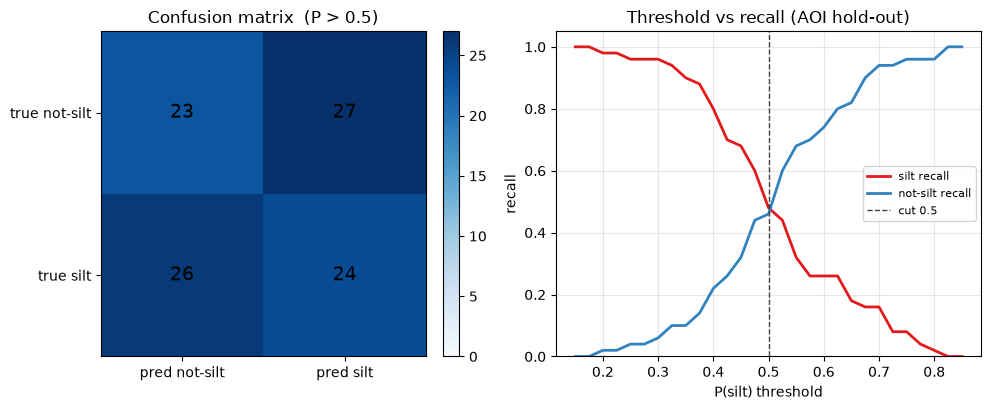

In [21]:
%matplotlib inline

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))

ax = axes[0]
im = ax.imshow(cm_arr, cmap="Blues", vmin=0)
ax.set_xticks([0, 1], ["pred not-silt", "pred silt"])
ax.set_yticks([0, 1], ["true not-silt", "true silt"])
ax.set_title(f"Confusion matrix  (P > {SILT_PROB_MIN})")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm_arr[i, j]}", ha="center", va="center", fontsize=14)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

ax = axes[1]
ts = np.linspace(0.15, 0.85, 29)
silt = true == 1
silt_rec, other_rec = [], []
for t in ts:
    pred_t = p1 > t
    tp = int(np.sum(silt & pred_t))
    fn = int(np.sum(silt & ~pred_t))
    tn = int(np.sum(~silt & ~pred_t))
    fp = int(np.sum(~silt & pred_t))
    silt_rec.append(tp / max(tp + fn, 1))
    other_rec.append(tn / max(tn + fp, 1))
ax.plot(ts, silt_rec, color="#e31a1c", lw=2, label="silt recall")
ax.plot(ts, other_rec, color="#3182bd", lw=2, label="not-silt recall")
ax.axvline(SILT_PROB_MIN, color="0.25", ls="--", lw=1, label=f"cut {SILT_PROB_MIN:g}")
ax.set_xlabel("P(silt) threshold")
ax.set_ylabel("recall")
ax.set_ylim(0, 1.05)
ax.set_title("Threshold vs recall (AOI hold-out)")
ax.legend(fontsize=8, loc="best")
ax.grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(OUT_DIR / "rf_silt_metrics.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Map predicted silt vs Dragonfly labels


In [17]:
valid_m = eligible
code_img = pred.multiply(2).add(silt_img).updateMask(valid_m).rename("code")
AGREE_VIS = {"min": 1, "max": 3, "palette": ["#a6611a", "#d7191c", "#1a9641"]}
agree = code_img.remap([1, 2, 3], [1, 2, 3]).selfMask()

# px = ee.Image.pixelArea().divide(1e6)

# def area_km2(mask):
#     v = px.updateMask(mask.And(valid_m)).reduceRegion(
#         ee.Reducer.sum(), aoi, AREA_SCALE, bestEffort=True, maxPixels=1e10,
#     ).get("area").getInfo()
#     return 0.0 if v is None else v

# map_stats = pd.Series({
#     "dragonfly_silt_km2": area_km2(silt_img),
#     "rf_silt_km2": area_km2(pred),
#     "both_km2": area_km2(pred.And(silt_img)),
#     "rf_only_km2": area_km2(pred.And(silt_img.Not())),
#     "label_only_km2": area_km2(silt_img.And(pred.Not())),
# }).round(3)
# print(map_stats.to_string())
# map_stats.to_csv(OUT_DIR / "rf_silt_map_areas.csv")

# Map = geemap.Map(center=cfg.MAP_CENTER, zoom=cfg.MAP_ZOOM, basemap="HYBRID")
# Map.addLayer(vv_post, {"min": -20, "max": 0}, f"VV post {post_time.date()}", False)
# Map.addLayer(dVV, {"min": -5, "max": 10, "palette": ["#ffffcc", "#fd8d3c", "#7f0000"]}, "ΔVV = pre − post", False)
# Map.addLayer(p_silt, {"min": 0, "max": 1, "palette": ["#ffffcc", "#fd8d3c", "#7f0000"]}, f"P(silt)  cut={SILT_PROB_MIN}", False)
# Map.addLayer(silt_img.selfMask(), {"palette": ["#a6611a"]}, "Dragonfly silt+slip (label)")
# Map.addLayer(df_flood_img.selfMask(), {"palette": ["#3182bd"]}, "Dragonfly flood (in class 0)", False)
# Map.addLayer(permanent.selfMask(), {"palette": ["#08519c"]}, "Permanent water (excluded)", False)
# Map.addLayer(pred.selfMask(), {"palette": ["#e31a1c"]}, f"RF silt (P > {SILT_PROB_MIN})", False)
# Map.addLayer(agree, AGREE_VIS, "Overlay (brown=label only, red=RF only, green=both)")
# Map


## 7. Figure


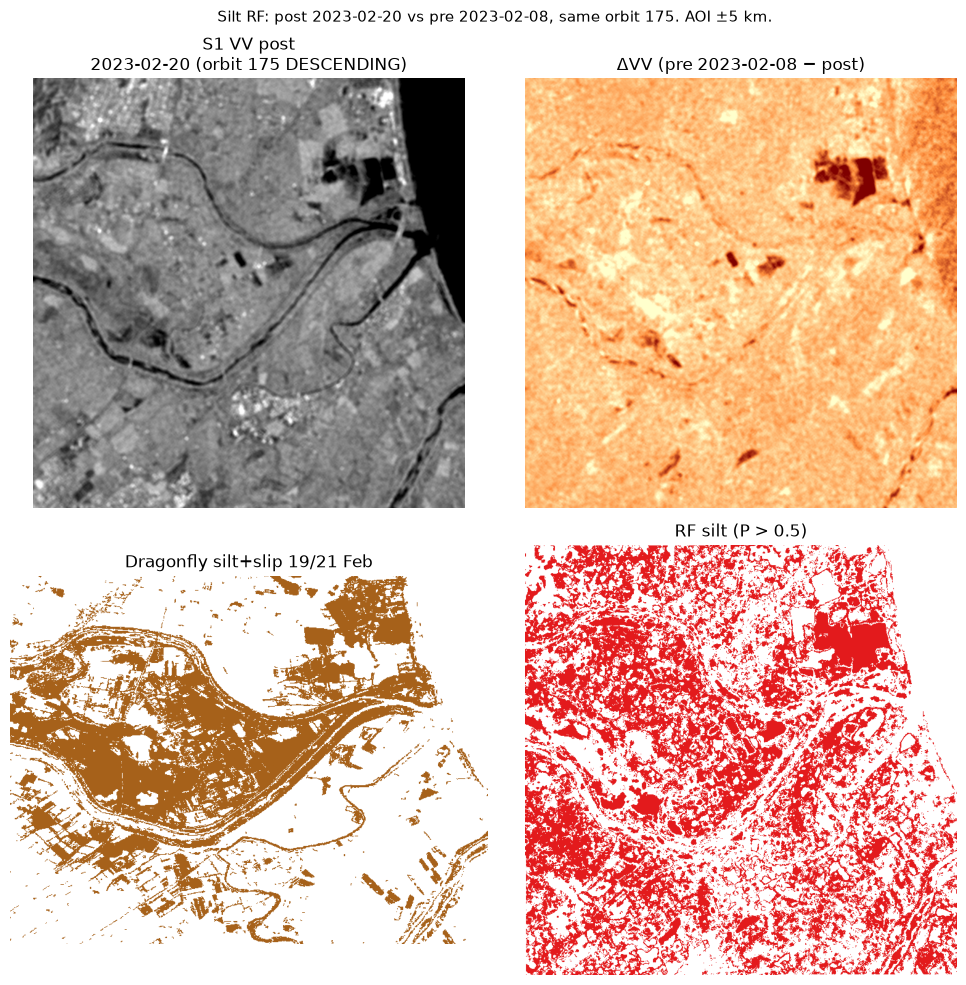

In [18]:
%matplotlib inline

def _thumb(img, vis):
    url = img.visualize(**vis).getThumbURL({"region": aoi, "dimensions": 700, "format": "png"})
    return np.array(Image.open(io.BytesIO(urlopen(url).read())))

vv_arr = _thumb(vv_post, {"min": -20, "max": 0, "palette": ["#000000", "#ffffff"]})
dv_arr = _thumb(dVV, {"min": -5, "max": 10, "palette": ["#ffffcc", "#fd8d3c", "#7f0000"]})
lab_arr = _thumb(silt_img.selfMask(), {"min": 0, "max": 1, "palette": ["#a6611a"]})
rf_arr = _thumb(pred.selfMask(), {"min": 0, "max": 1, "palette": ["#e31a1c"]})

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes[0, 0].imshow(vv_arr)
axes[0, 0].set_title(f"S1 VV post\n{post_time.date()} (orbit {post_orbit} {post_pass})")
axes[0, 1].imshow(dv_arr)
axes[0, 1].set_title(f"ΔVV (pre {pre_time.date()} − post)")
axes[1, 0].imshow(lab_arr)
axes[1, 0].set_title("Dragonfly silt+slip 19/21 Feb")
axes[1, 1].imshow(rf_arr)
axes[1, 1].set_title(f"RF silt (P > {SILT_PROB_MIN})")
for ax in axes.ravel():
    ax.set_axis_off()
fig.suptitle(
    f"Silt RF: post {post_time.date()} vs pre {pre_time.date()}, same orbit {post_orbit}. "
    f"AOI ±{cfg.AOI_RADIUS_KM:g} km.",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "rf_silt_sameorbit.png", dpi=200, bbox_inches="tight")
plt.show()


## Notes

- **Same-orbit change** avoids comparing different look directions. Pre is before `FLOOD_PEAK_DATE` so the 14 Feb flood scene is not the baseline.
- **Labels are another model** (Dragonfly S2 silt **and slip**). Scores are agreement with that product.
- **Spatial split:** train on a ±25 km buffer **excluding** the mapping AOI; test only inside the AOI. Still one event; it does not prove transfer to another cyclone.
- Classes are **silt/slip vs other**. Dragonfly `flood` may fall in **other**. Permanent water is excluded from train, test, and the map so the tree is not trained on rivers/lakes.
